# Task 1: Data Exploration

This notebook follows the simple steps used in the lecture. A few basic checks are added for missing values, categories, and the stroke label.

## 1. Import libraries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files

## 2. Upload the dataset

Upload `healthcare-dataset-stroke-data.csv` from your computer.

In [2]:
uploaded = files.upload()

file_name = next(iter(uploaded))
data = pd.read_csv(file_name)

Saving healthcare-dataset-stroke-data.csv to healthcare-dataset-stroke-data.csv


## 3. Show the dataset shape and first rows

In [3]:
print(data.shape)
data.head()

(5110, 12)


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


## 4. Show general information about the dataset

In [4]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   object 
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   object 
 6   work_type          5110 non-null   object 
 7   Residence_type     5110 non-null   object 
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   object 
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), object(5)
memory usage: 479.2+ KB


## 5. Show histograms

Histograms are used for the numeric columns. `id` is left out because it is only an identifier.

Column: id


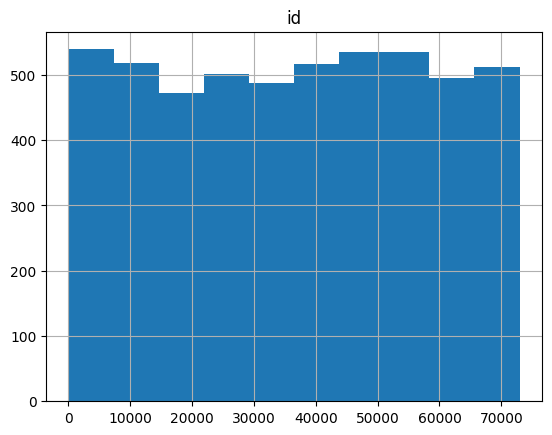

Column: age


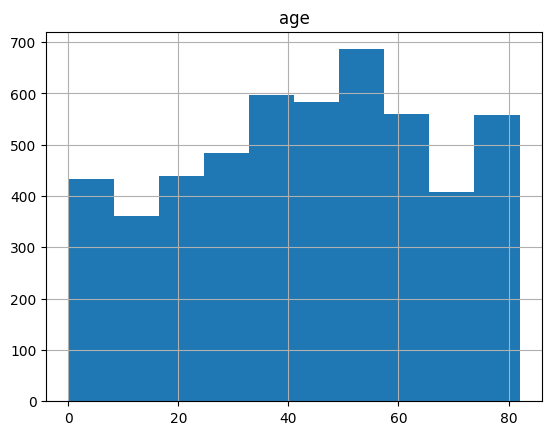

Column: hypertension


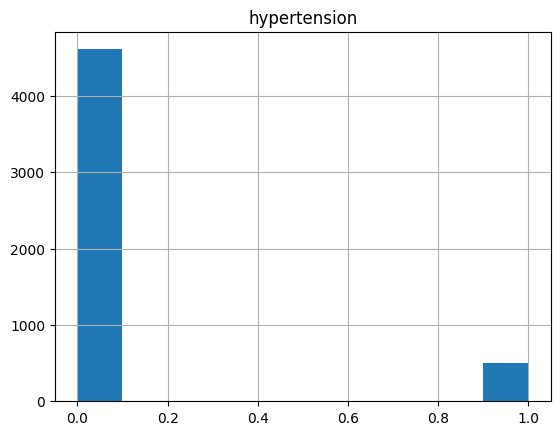

Column: heart_disease


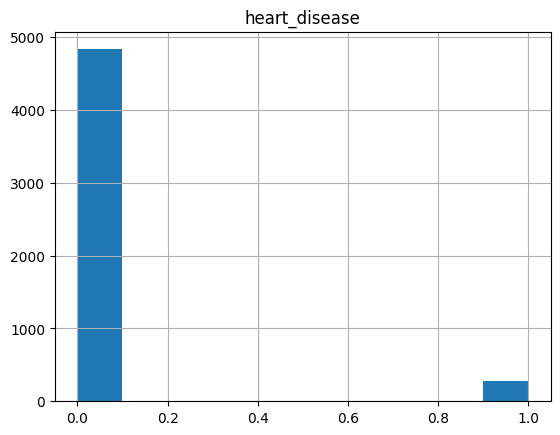

Column: avg_glucose_level


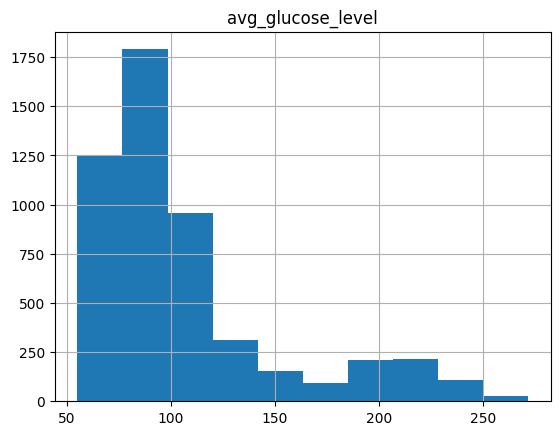

Column: bmi


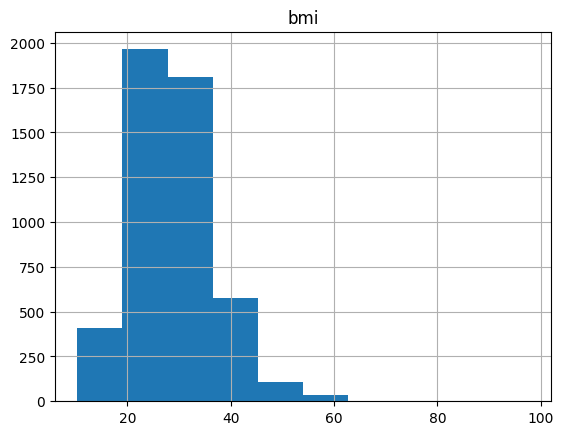

Column: stroke


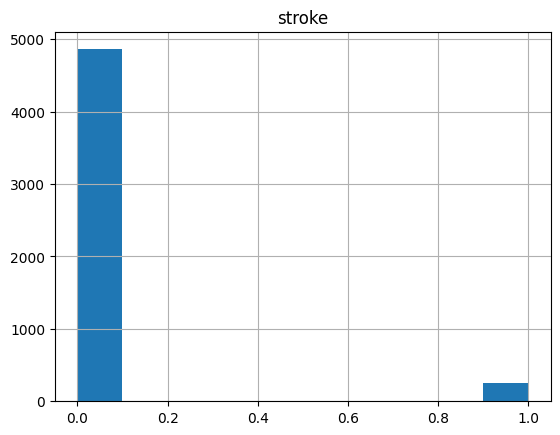

In [5]:
columns = ['age', 'hypertension', 'heart_disease', 'avg_glucose_level', 'bmi', 'stroke']

for col in columns:
    print('Column:', col)
    data[col].hist()
    plt.title(col)
    plt.show()

## 6. Missing values and stroke counts

In [ ]:
print('Duplicate rows:', data.duplicated().sum())
print(data.isna().sum())
print(data['stroke'].value_counts())
print(data[['age', 'avg_glucose_level', 'bmi']].describe())


## 7. Count the text columns

Bar charts are used because these columns are categories, not numbers.

In [ ]:
text_columns = ['gender', 'ever_married', 'work_type', 'Residence_type', 'smoking_status']

for col in text_columns:
    print(col)
    print(data[col].value_counts())
    data[col].value_counts().plot(kind='bar')
    plt.title(col)
    plt.show()


## 8. Compare a few columns with stroke

`mean()` of the stroke column is the share of patients in that group who have stroke = 1.

In [ ]:
print(data.groupby('gender')['stroke'].mean())
print(data.groupby('hypertension')['stroke'].mean())
print(data.groupby('heart_disease')['stroke'].mean())
print(data.groupby('smoking_status')['stroke'].mean())
print(data.groupby('stroke')[['age', 'avg_glucose_level', 'bmi']].mean())

data['stroke'].value_counts().plot(kind='bar')
plt.title('stroke')
plt.show()


## 9. Short reading

The file has 5,110 rows. BMI is the only column with missing values: 201 rows. Stroke = 1 has 249 rows, and stroke = 0 has 4,861 rows. Most patients did not have a stroke.

Older patients, and patients with hypertension or heart disease, have a higher share of stroke = 1 in this file. That is a pattern in the data, not proof of a cause.

`Unknown` in smoking_status means the information is missing. It is not the same as never smoked. The work type in the file is `Govt_job`.

## 10. Preprocess the dataset

This follows the lecturer's steps: convert text columns into dummy columns, fill missing BMI with 0, and remove the ID column.

Filling BMI with 0 matches the lecture code. A BMI of 0 is not a real BMI, so mention this limit in the report.

In [6]:
categorical_cols = ['gender', 'ever_married', 'work_type',
                    'Residence_type', 'smoking_status']

encoded = pd.get_dummies(data[categorical_cols], prefix=categorical_cols)
data = pd.concat([encoded, data], axis=1)
data.drop(categorical_cols, axis=1, inplace=True)
data['bmi'] = data['bmi'].fillna(0)
data.drop(['id'], axis=1, inplace=True)

## 11. Show the preprocessed dataset

In [7]:
data.head()

,gender_Female,gender_Male,gender_Other,ever_married_No,ever_married_Yes,work_type_Govt_job,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,...,smoking_status_Unknown,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
0,False,True,False,False,True,False,False,True,False,False,...,False,True,False,False,67.0,0,1,228.69,36.6,1
1,True,False,False,False,True,False,False,False,True,False,...,False,False,True,False,61.0,0,0,202.21,0.0,1
2,False,True,False,False,True,False,False,True,False,False,...,False,False,True,False,80.0,0,1,105.92,32.5,1
3,True,False,False,False,True,False,False,True,False,False,...,False,False,False,True,49.0,0,0,171.23,34.4,1
4,True,False,False,False,True,False,False,False,True,False,...,False,False,True,False,79.0,1,0,174.12,24.0,1


In [ ]:
print('Preprocessed shape:', data.shape)
print(data.info())
print(data.describe())
print('Stroke counts:')
print(data['stroke'].value_counts())
print(data.head())